<a href="https://colab.research.google.com/github/AlexBecerril/miaad-sem1/blob/main/Actividad_arbol_de_decision_para_regresion_275333.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Programación para Analítica Descriptiva y Predictiva — MIAAD, UACJ**


**Nombre:Edgar** Alejandro Becerril Caballero

**Matricula:** 275333

**Ficha técnica**

| | |
|---|---|
| **Modalidad** | Individual |
| **Entorno** | Google Colab |
| **Dataset** | California Housing, disponible en scikit-learn |
| **Modelo** | Árbol de Decisión (`DecisionTreeRegressor`) |
| **Puntaje total** | 100 puntos |
| **Fecha de entrega** | 28/10/2026 |

#**Actividad: Árbol de Decisión para Regresión**

##**Objetivo**
Analizar el comportamiento de un modelo de árbol de decisión en un problema de regresión, evaluando su capacidad de generalización mediante el estudio del sobreajuste, la profundidad del árbol y la poda.

##**Dataset**
Se utilizará el dataset California Housing, disponible en scikit-learn.

### **Carga y exploración de datos**

* Cargar el dataset en un DataFrame
* Identificar la variable objetivo (MedHouseVal)
* Analizar la estructura del dataset (info, describe)
* Visualizar la distribución de la variable objetivo

In [ ]:
# Se importan las librerías necesarias para la manipulación de datos,
# la visualización y la construcción y evaluación de modelos de regresión.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
# Se importa la función para cargar el dataset California Housing
# directamente desde scikit-learn.
from sklearn.datasets import fetch_california_housing

# Se carga el dataset como un DataFrame de pandas, incluyendo
# las variables predictoras y la variable objetivo.
california = fetch_california_housing(as_frame=True)
df = california.frame

# Se muestran las primeras 10 observaciones para conocer la estructura
# del conjunto de datos y los valores de sus variables.
df.head(10)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
5,4.0368,52.0,4.761658,1.103627,413.0,2.139896,37.85,-122.25,2.697
6,3.6591,52.0,4.931907,0.951362,1094.0,2.128405,37.84,-122.25,2.992
7,3.1200,52.0,4.797527,1.061824,1157.0,1.788253,37.84,-122.25,2.414
8,2.0804,42.0,4.294118,1.117647,1206.0,2.026891,37.84,-122.26,2.267
9,3.6912,52.0,4.970588,0.990196,1551.0,2.172269,37.84,-122.25,2.611


In [ ]:
# Se consulta la información general del DataFrame para identificar
# el número de observaciones, las columnas, sus tipos de datos
# y la presencia de valores nulos.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [ ]:
# Se obtiene un resumen estadístico de las variables numéricas,
# incluyendo media, desviación estándar, mínimo, máximo y cuartiles.
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


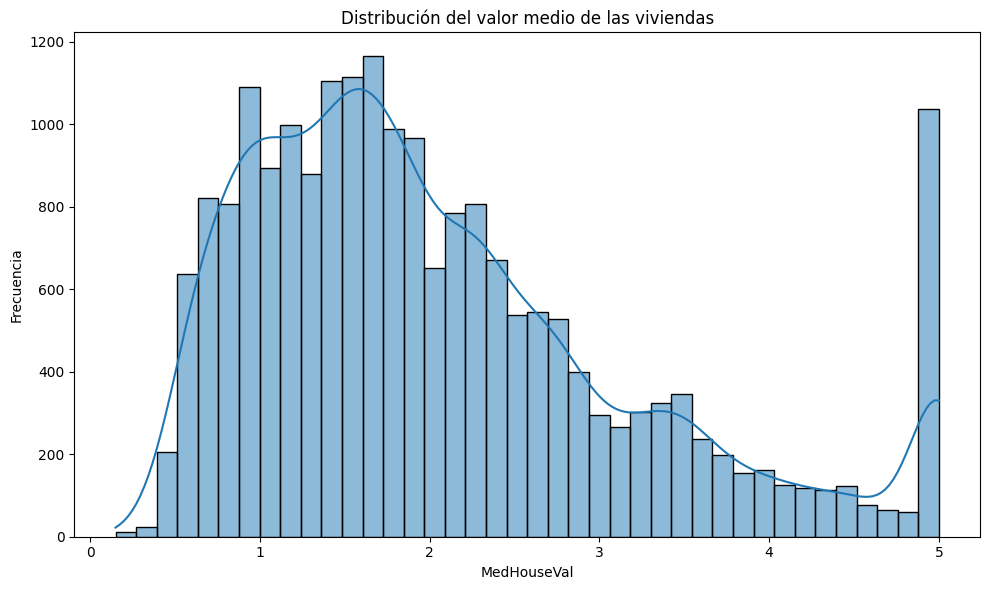

In [ ]:
# Se visualiza la distribución de la variable objetivo MedHouseVal
# mediante un histograma y una curva de densidad para observar
# la concentración de valores, su dispersión y posible asimetría.
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='MedHouseVal', bins=40, kde=True)

plt.title('Distribución del valor medio de las viviendas')
plt.xlabel('MedHouseVal')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

### Análisis de distribución

El conjunto de datos presenta una asimetría positiva, ya que la mayor concentración de observaciones se encuentra aproximadamente entre 0.7 y 2.5, mientras que la distribución se extiende hacia valores más altos. También se observa una acumulación considerable de observaciones en el valor 5, que corresponde al límite superior de la variable objetivo.

### **Preparación de datos**

* Definir:
  * X: variables predictoras
  * y: variable objetivo
* Dividir los datos en entrenamiento (80%) y prueba (20%)

In [ ]:
# Variables predictoras: se utilizan las ocho variables disponibles para
# predecir el valor medio de las viviendas (MedHouseVal).
# La variable objetivo se excluye de X para evitar utilizarla como entrada
# del modelo al momento de realizar las predicciones.
variables = [
    "MedInc", "HouseAge", "AveRooms", "AveBedrms",
    "Population", "AveOccup", "Latitude", "Longitude"
]

X = df[variables].copy()
y = df["MedHouseVal"].copy()

# Se imprimen los nombres de las variables predictoras y las estadísticas
# descriptivas de la variable objetivo para conocer su distribución.
print(f"\nVariables predictoras: {list(X.columns)}")
print("\nEstadísticas de la variable objetivo (MedHouseVal):")
print(y.describe())


Variables predictoras: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Estadísticas de la variable objetivo (MedHouseVal):
count    20640.000000
mean         2.068558
std          1.153956
min          0.149990
25%          1.196000
50%          1.797000
75%          2.647250
max          5.000010
Name: MedHouseVal, dtype: float64


In [ ]:
# Se realiza una divición hold-out del conjunto de datos,
# conservando el 80% para entrenamiento y el 20% para prueba
# con un random_state 42 para reproducibilidad
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

### **Modelo base**
* Entrenar un árbol de decisión sin restricciones (max_depth=None)
* Evaluar el modelo usando:
  * RMSE
  * R²
* Comparar desempeño en entrenamiento y prueba
* Determinar si existe sobreajuste

In [ ]:
# Se define un árbol de decisión para regresión sin restricciones de profundidad.
arbol_base = DecisionTreeRegressor(max_depth=None, random_state=0)

# Se entrena el modelo utilizando las variables predictoras y los valores
# reales de la variable objetivo correspondientes al conjunto de entrenamiento.
arbol_base.fit(X_train, y_train)

# Se generan predicciones para los conjuntos de entrenamiento y prueba.
y_pred_train = arbol_base.predict(X_train)
y_pred_test = arbol_base.predict(X_test)

# Se calcula el RMSE para ambos conjuntos, que mide el error promedio
# de las predicciones en las mismas unidades de la variable objetivo.
# Un valor menor indica que las predicciones se encuentran más cerca
# de los valores reales.
rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))

# Se calcula el R² para ambos conjuntos, que indica qué proporción
# de la variabilidad de la variable objetivo explica el modelo.
# Un valor más cercano a 1 indica un mejor ajuste; puede ser negativo
# cuando el modelo predice peor que una referencia basada en la media.
r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)

# Se imprimen el número de observaciones de entrenamiento y prueba,
# así como las métricas obtenidas en ambos conjuntos para comparar
# el ajuste del modelo y evaluar si existe sobreajuste.
print("Número de observaciones de entrenamiento:", X_train.shape[0])
print("Número de observaciones de prueba:", X_test.shape[0])

print("\nDesempeño en entrenamiento:")
print("RMSE:", rmse_train)
print("R²:", r2_train)

print("\nDesempeño en prueba:")
print("RMSE:", rmse_test)
print("R²:", r2_test)


Número de observaciones de entrenamiento: 16512
Número de observaciones de prueba: 4128

Desempeño en entrenamiento:
RMSE: 3.0144329835028385e-16
R²: 1.0

Desempeño en prueba:
RMSE: 0.7077070144581036
R²: 0.617791676774418


### Análisis de desempeño

En este caso, se puede apreciar claramente que el modelo se ajustó demasiado al conjunto de entrenamiento, ya que el valor de R² es igual a 1 y el RMSE es prácticamente 0. Esto ocurre porque el árbol de regresión no tiene restricciones de profundidad, por lo que puede generar tantas divisiones como sean necesarias para ajustarse a los datos de entrenamiento.

Por otro lado, al evaluar el modelo con los datos de prueba, el RMSE aumenta a aproximadamente 0.708 y el R² disminuye a 0.618. Esta diferencia indica que el modelo no logra generalizar con la misma precisión a datos que no utilizó durante el entrenamiento, lo que confirma que existe un sobreajuste.

### **Análisis Bias–Variance**
* Entrenar múltiples modelos variando el parámetro max_depth de 1 a 21.
* Graficar el error (RMSE) en entrenamiento y prueba
* Identificar el punto donde el modelo generaliza mejor

In [ ]:
# Hiperparámetros del árbol
param_grid = {
    'max_depth': np.arange(1, 22)
}

resultados = []

# Se entrena un árbol de regresión para cada profundidad y se evalúa
# su desempeño tanto en entrenamiento como en prueba.
for profundidad in param_grid['max_depth']:

    # Se crea y entrena el árbol con la profundidad seleccionada.
    arbol = DecisionTreeRegressor(
        max_depth=profundidad,
        random_state=0
    )
    arbol.fit(X_train, y_train)

    # Se generan predicciones para ambos conjuntos de datos.
    pred_train = arbol.predict(X_train)
    pred_test = arbol.predict(X_test)

    # Se calculan RMSE y R² para comparar el ajuste y la capacidad
    # de generalización de cada modelo.
    resultados.append({
        "max_depth": profundidad,
        "RMSE_train": np.sqrt(mean_squared_error(y_train, pred_train)),
        "RMSE_test": np.sqrt(mean_squared_error(y_test, pred_test)),
        "R2_train": r2_score(y_train, pred_train),
        "R2_test": r2_score(y_test, pred_test)
    })

# Se organizan los resultados en una tabla ordenada por profundidad
# para identificar las diferencias entre los modelos.
resultados_df = pd.DataFrame(resultados)
resultados_df

,max_depth,RMSE_train,RMSE_test,R2_train,R2_test
0,1,0.955523,0.971666,0.316997,0.279511
1,2,0.855859,0.868483,0.452045,0.424406
2,3,0.785957,0.801505,0.537898,0.509763
3,4,0.741534,0.764464,0.588659,0.554029
4,5,0.695948,0.724234,0.637679,0.599732
5,6,0.655831,0.705184,0.678245,0.620513
6,7,0.615396,0.675711,0.716698,0.651570
7,8,0.566211,0.650086,0.760173,0.677496
8,9,0.517161,0.642393,0.799926,0.685084
9,10,0.469964,0.651713,0.834778,0.675880


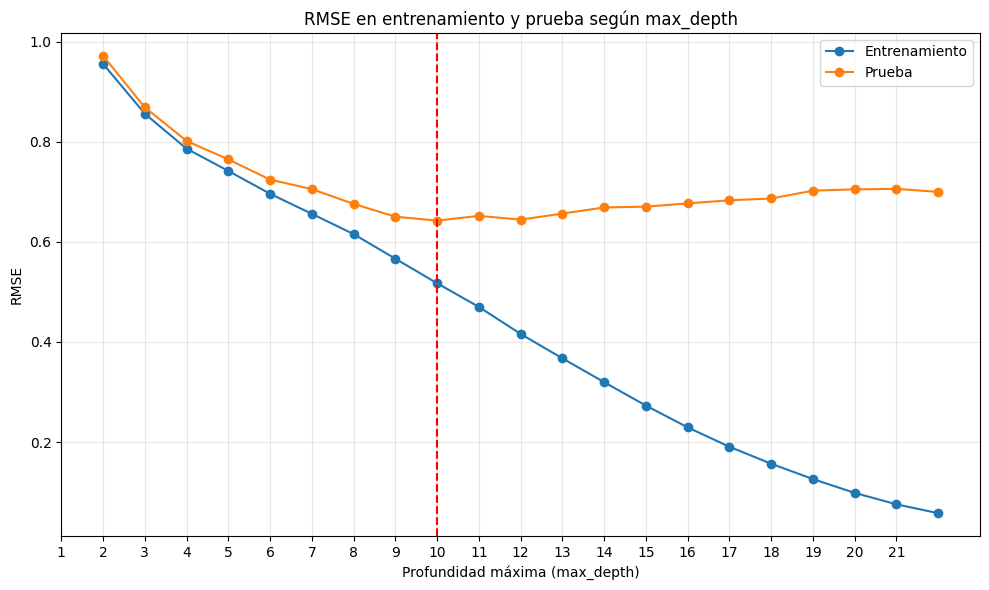

In [ ]:
# Se crea una figura para comparar el error de entrenamiento y prueba
# en función de la profundidad máxima del árbol.
plt.figure(figsize=(10, 6))

# Se grafica el RMSE de ambos conjuntos para observar cómo evoluciona
# el error conforme aumenta la profundidad del árbol.
plt.plot(resultados_df["max_depth"], resultados_df["RMSE_train"],
         marker="o", label="Entrenamiento")
plt.plot(resultados_df["max_depth"], resultados_df["RMSE_test"],
         marker="o", label="Prueba")

# Se agregan títulos y etiquetas para facilitar la interpretación.
plt.title("RMSE en entrenamiento y prueba según max_depth")
plt.xlabel("Profundidad máxima (max_depth)")
plt.ylabel("RMSE")
plt.xticks(range(len(resultados_df)), resultados_df["max_depth"])
plt.legend()
plt.grid(True, alpha=0.3)

# Se agrega una línea vertical para destacar la profundidad 9.
plt.axvline(x=9, color="red", linestyle="--")

plt.tight_layout()
plt.show()

## Análisis de Desempeño

El error tiende a ser alto cuando la profundidad del árbol es baja. Conforme se aumenta la profundidad, el RMSE disminuye progresivamente para el conjunto de entrenamiento. Sin embargo, para el conjunto de prueba, el error disminuye hasta cierto punto y después comienza a aumentar en general, lo que indica que el modelo empieza a ajustarse demasiado a los datos de entrenamiento.

En este caso específico, podemos encontrar ese punto en un max_depth de **9**, donde se obtiene el menor RMSE de prueba (0.642393) y el mayor R² de prueba (0.685084). A partir de esa profundidad, el desempeño en prueba tiende a deteriorarse, mientras que el modelo continúa mejorando sus métricas de entrenamiento. Esto evidencia un sobreajuste progresivo y sugiere que una profundidad de **9** ofrece el mejor equilibrio entre ajuste y capacidad de generalización entre los modelos evaluados.

### **Poda del árbol**
* Aplicar cost-complexity pruning (ccp_alpha)
* Evaluar distintos valores de ccp_alpha con ccp_alphas = ccp_alphas[::5]
* Analizar su efecto en el error del modelo

In [ ]:
# Se obtiene la ruta de poda por complejidad de costo, que incluye
# los valores de ccp_alpha y la impureza total de las hojas.
ruta_poda = arbol_base.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = ruta_poda.ccp_alphas

print("Número de valores de ccp_alpha:", len(ccp_alphas))

# Se selecciona uno de cada cinco (50) valores para reducir el número
# de modelos que se evaluarán.
ccp_alphas = ccp_alphas[::50]

print("Número de valores de ccp_alpha a evaluar:", len(ccp_alphas))
print("Valores de ccp_alpha:", ccp_alphas)

Número de valores de ccp_alpha: 14838
Número de valores de ccp_alpha a evaluar: 297
Valores de ccp_alpha: [0.00000000e+00 3.02810074e-11 3.02810078e-11 3.02810078e-11
 1.21124031e-10 1.21124031e-10 2.72529070e-10 2.72529070e-10
 2.72529070e-10 4.84496124e-10 4.84496124e-10 7.57025194e-10
 7.57025194e-10 7.57025194e-10 1.09011628e-09 1.09011628e-09
 1.48376938e-09 1.48376938e-09 1.93798450e-09 1.93798450e-09
 1.97835917e-09 2.45276163e-09 2.45276163e-09 3.02810078e-09
 3.02810078e-09 3.66400194e-09 3.66400194e-09 4.03746770e-09
 4.36046512e-09 4.85000807e-09 5.11749031e-09 5.33955103e-09
 5.93507752e-09 6.30854328e-09 6.81322674e-09 7.75193798e-09
 7.75193798e-09 8.75121124e-09 8.75121124e-09 9.81104651e-09
 9.81104651e-09 1.09314438e-08 1.16682817e-08 1.21124031e-08
 1.33539244e-08 1.33539244e-08 1.46560078e-08 1.46560078e-08
 1.60186531e-08 1.74418605e-08 1.74418605e-08 1.89256298e-08
 1.89256298e-08 2.04699612e-08 2.20748547e-08 2.22969154e-08
 2.37403101e-08 2.54410933e-08 2.6253633

In [ ]:
# Se crea una lista para almacenar las métricas de cada árbol podado.
resultados_poda = []

# Se entrena un árbol para cada valor de ccp_alpha y se evalúa
# su desempeño en los conjuntos de entrenamiento y prueba.
for alpha in ccp_alphas:

    # Se crea el árbol aplicando el nivel de poda seleccionado.
    arbol = DecisionTreeRegressor(
        random_state=0,
        ccp_alpha=alpha
    )
    arbol.fit(X_train, y_train)

    # Se generan predicciones para ambos conjuntos de datos.
    pred_train = arbol.predict(X_train)
    pred_test = arbol.predict(X_test)

    # Se calculan RMSE y R² para comparar el ajuste y la generalización.
    resultados_poda.append({
        "ccp_alpha": alpha,
        "RMSE_train": np.sqrt(mean_squared_error(y_train, pred_train)),
        "RMSE_test": np.sqrt(mean_squared_error(y_test, pred_test)),
        "R2_train": r2_score(y_train, pred_train),
        "R2_test": r2_score(y_test, pred_test)
    })

# Se organizan los resultados en un DataFrame para facilitar su análisis.
resultados_poda_df = pd.DataFrame(resultados_poda)
resultados_poda_df.head()

,ccp_alpha,RMSE_train,RMSE_test,R2_train,R2_test
0,0.000000e+00,3.014433e-16,0.707707,1.0,0.617792
1,3.028101e-11,5.507963e-06,0.707707,1.0,0.617792
2,3.028101e-11,4.006183e-05,0.707707,1.0,0.617792
3,3.028101e-11,5.530315e-05,0.707706,1.0,0.617792
4,1.211240e-10,9.002929e-05,0.707706,1.0,0.617793


In [ ]:
# Se identifica el alpha que obtuvo el menor RMSE en el conjunto de prueba.
mejor_poda = resultados_poda_df.loc[
    resultados_poda_df["RMSE_test"].idxmin()
]

print(mejor_poda)

ccp_alpha     0.000336
RMSE_train    0.493342
RMSE_test     0.631955
R2_train      0.817930
R2_test       0.695235
Name: 292, dtype: float64


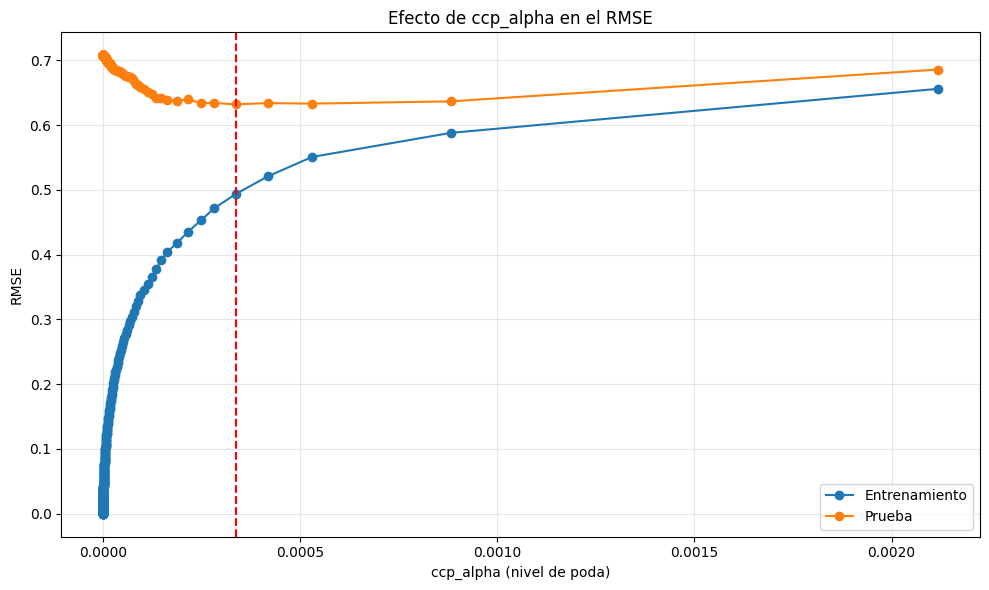

In [ ]:
# Se comparan los errores de entrenamiento y prueba según
# el nivel de poda aplicado al árbol.
plt.figure(figsize=(10, 6))

plt.plot(
    resultados_poda_df["ccp_alpha"],
    resultados_poda_df["RMSE_train"],
    marker="o",
    label="Entrenamiento"
)
plt.plot(
    resultados_poda_df["ccp_alpha"],
    resultados_poda_df["RMSE_test"],
    marker="o",
    label="Prueba"
)

plt.title("Efecto de ccp_alpha en el RMSE")
plt.xlabel("ccp_alpha (nivel de poda)")
plt.ylabel("RMSE")
plt.legend()
plt.grid(True, alpha=0.3)

# Se agrega una línea vertical para destacar.
plt.axvline(x=0.000336, color="red", linestyle="--")

plt.tight_layout()
plt.show()

### Análisis de Desempeño

En la gráfica se observa que, sin poda, el árbol obtiene un RMSE de entrenamiento prácticamente igual a cero, lo que indica que se ajusta casi perfectamente a los datos utilizados durante el entrenamiento. Sin embargo, el RMSE de prueba comienza alrededor de 0.71, lo que evidencia una diferencia importante entre el ajuste del modelo y su capacidad de generalización.

Conforme aumenta ccp_alpha, el RMSE de entrenamiento aumenta debido a que se eliminan ramas y el modelo se vuelve más simple. Por otro lado, el RMSE de prueba disminuye inicialmente, lo que indica que la poda ayuda a reducir el sobreajuste. Después alcanza un mínimo y comienza a aumentar ligeramente, señal de que una poda excesiva puede provocar subajuste.

El nivel de poda óptimo entre los valores evaluados corresponde al que obtiene el menor RMSE en el conjunto de prueba. Este punto permite encontrar un mejor equilibrio entre el ajuste a los datos de entrenamiento y la capacidad de generalizar a datos nuevos.

In [ ]:
# Se crea el árbol de decisión con el valor de ccp_alpha
# que obtuvo el menor RMSE en el conjunto de prueba.
mejor_modelo = DecisionTreeRegressor(
    ccp_alpha=0.000336,
    random_state=0
)

# Se entrena el modelo con los datos de entrenamiento.
mejor_modelo.fit(X_train, y_train)

# Se obtiene la importancia de cada variable predictora.
importancias = pd.DataFrame({
    "Variable": X_train.columns,
    "Importancia": mejor_modelo.feature_importances_
})

# Se ordenan las variables de mayor a menor importancia.
importancias = importancias.sort_values(
    by="Importancia",
    ascending=False
)

importancias

,Variable,Importancia
0,MedInc,0.620706
5,AveOccup,0.128235
6,Latitude,0.080967
7,Longitude,0.066248
1,HouseAge,0.043064
2,AveRooms,0.037413
4,Population,0.013697
3,AveBedrms,0.009670


### **Interpretación de resultados**
#### **Responder de manera justificada:**

**¿El modelo base presenta sobreajuste? Explique**  

El modelo base sí presenta sobreajuste. Al definirlo y entrenarlo sin restricciones de profundidad, tiende a ajustarse demasiado al conjunto de datos de entrenamiento, lo que afecta su capacidad para predecir valores de datos que no ha visto antes. Esto se puede observar en el RMSE prácticamente igual a cero y el R² igual a 1 en entrenamiento, mientras que en prueba el RMSE aumenta y el R² disminuye.  

**¿Cómo afecta la profundidad del árbol al error?**  

La profundidad del árbol define el número de niveles de decisión del mismo. Entre mayor profundidad tenga, mejor se ajustará al conjunto de datos de entrenamiento, por lo que el error sobre este conjunto tenderá a disminuir. Por otro lado, al evaluar el error sobre el conjunto de prueba, generalmente se observa que al aumentar la profundidad el modelo mejora sus predicciones hasta cierto punto. A partir de ahí, puede comenzar el sobreajuste, por lo que su capacidad de generalización disminuye y el error de prueba tiende a aumentar.

**¿Qué efecto tiene la poda en el modelo?**

La poda permite reducir la complejidad del árbol al eliminar ramas que aportan poca mejora al ajuste del modelo. En este caso, al utilizar un ccp_alpha de aproximadamente 0.000336, se obtiene un RMSE de 0.4933 en entrenamiento y de 0.6320 en prueba. Aunque el error de entrenamiento aumenta respecto al árbol sin poda, el error de prueba disminuye, lo que indica que la poda ayuda a reducir el sobreajuste y mejora la capacidad de generalización del modelo.

**¿Cuál configuración produce el mejor desempeño?**

En las pruebas realizadas, la configuración con ccp_alpha = 0.000336 obtuvo un RMSE de prueba de aproximadamente 0.6320 y un R² de 0.6952. En comparación con el árbol cuya profundidad máxima es 9, que obtuvo un RMSE de prueba de 0.6424 y un R² de 0.6851, el modelo podado presenta un mejor desempeño en el conjunto de prueba.

**¿Qué variables son más relevantes según el modelo?**

Según las importancias calculadas por el árbol de decisión podado, la variable más relevante es MedInc (ingreso medio de la zona), con una importancia de aproximadamente 62.1%. Esto indica que esta variable tiene la mayor contribución para predecir el valor medio de las viviendas.

En segundo lugar se encuentra AveOccup (ocupación media por vivienda), con 12.8%, seguida de Latitude y Longitude, con 8.1% y 6.6%, respectivamente. El resto de las variables presentan importancias considerablemente menores, especialmente Population y AveBedrms, con 1.4% y 1.0%.

Estos resultados sugieren que el ingreso medio de la zona es el principal factor utilizado por el modelo para estimar el valor de las viviendas, mientras que la ocupación y la ubicación geográfica también contribuyen a sus predicciones.